# Loan Default Prediction

UML501 Machine Learning project

Aabhas Khandelwal (1024030673), Joy Soni (1024030674)

We predict whether a loan applicant will default using the UCI German Credit dataset. We train Logistic Regression, Decision Tree and Random Forest, and judge them on recall for defaulters, because approving someone who later defaults costs a bank more than turning away a good applicant.

In [ ]:
!pip install -q -U ucimlrepo scikit-learn

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, make_scorer,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

os.makedirs("figures", exist_ok=True)

## 1. Load the data

If `data/german.data` is in the folder we read it directly, otherwise we download the same file from the UCI repository. The target is 1 = good and 2 = bad, so we turn it into 1 = default and 0 = no default.

In [3]:
cols = ["status_checking", "duration_months", "credit_history", "purpose", "credit_amount",
        "savings", "employment_since", "installment_rate", "personal_status_sex",
        "other_debtors", "residence_since", "property", "age", "other_installment_plans",
        "housing", "existing_credits", "job", "num_dependents", "telephone", "foreign_worker"]

if os.path.exists("data/german.data"):
    raw = pd.read_csv("data/german.data", sep=" ", header=None)
    X, target = raw.iloc[:, :20].copy(), raw.iloc[:, 20]
else:
    data = fetch_ucirepo(id=144)
    X, target = data.data.features.copy(), data.data.targets.iloc[:, 0]

X.columns = cols
y = (target == 2).astype(int).rename("default")
print(X.shape, y.shape)

(1000, 20) (1000,)


## 2. Make the categories readable

The raw file stores categories as codes like A11 or A43. We map them to the meanings given in the UCI documentation (amounts are in Deutsche Mark). The model does not care about the names, but it makes the plots readable.

In [4]:
labels = {
    "status_checking": {"A11": "< 0 DM", "A12": "0 to 200 DM", "A13": ">= 200 DM", "A14": "no checking account"},
    "credit_history": {"A30": "no credits / all paid", "A31": "all paid at this bank",
                       "A32": "existing paid till now", "A33": "delays in the past",
                       "A34": "critical account"},
    "purpose": {"A40": "new car", "A41": "used car", "A42": "furniture", "A43": "radio/TV",
                "A44": "appliances", "A45": "repairs", "A46": "education", "A48": "retraining",
                "A49": "business", "A410": "other"},
    "savings": {"A61": "< 100 DM", "A62": "100 to 500 DM", "A63": "500 to 1000 DM",
                "A64": ">= 1000 DM", "A65": "unknown / none"},
    "employment_since": {"A71": "unemployed", "A72": "< 1 year", "A73": "1 to 4 years",
                         "A74": "4 to 7 years", "A75": ">= 7 years"},
    "personal_status_sex": {"A91": "male divorced", "A92": "female div/married", "A93": "male single",
                            "A94": "male married", "A95": "female single"},
    "other_debtors": {"A101": "none", "A102": "co-applicant", "A103": "guarantor"},
    "property": {"A121": "real estate", "A122": "savings/insurance", "A123": "car or other",
                 "A124": "unknown / none"},
    "other_installment_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
    "housing": {"A151": "rent", "A152": "own", "A153": "for free"},
    "job": {"A171": "unskilled non-resident", "A172": "unskilled resident",
            "A173": "skilled employee", "A174": "management / self-employed"},
    "telephone": {"A191": "none", "A192": "yes"},
    "foreign_worker": {"A201": "yes", "A202": "no"},
}

for col, mapping in labels.items():
    X[col] = X[col].map(mapping)

print("Unmapped values:", X.isnull().sum().sum())
X.head()

Unmapped values: 0


,status_checking,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker
0,< 0 DM,6,critical account,radio/TV,1169,unknown / none,>= 7 years,4,male single,none,4,real estate,67,none,own,2,skilled employee,1,yes,yes
1,0 to 200 DM,48,existing paid till now,radio/TV,5951,< 100 DM,1 to 4 years,2,female div/married,none,2,real estate,22,none,own,1,skilled employee,1,none,yes
2,no checking account,12,critical account,education,2096,< 100 DM,4 to 7 years,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,< 0 DM,42,existing paid till now,furniture,7882,< 100 DM,4 to 7 years,2,male single,guarantor,4,savings/insurance,45,none,for free,1,skilled employee,2,none,yes
4,< 0 DM,24,delays in the past,new car,4870,< 100 DM,1 to 4 years,3,male single,none,4,unknown / none,53,none,for free,2,skilled employee,2,none,yes


## 3. Data cleaning

We check four things: blank cells, duplicate rows, missing information hidden inside categories, and outliers.

In [5]:
print("Blank cells:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())

Blank cells: 0
Duplicate rows: 0


There are no blank cells, but some categories are really missing information. "unknown / none" for savings or property means the bank did not know. We check whether these rows behave differently before deciding what to do with them.

In [6]:
hidden = {"savings": "unknown / none", "property": "unknown / none"}
rows = {}
for col, val in hidden.items():
    mask = X[col] == val
    rows[f"{col} = {val}"] = {"Rows": mask.sum(),
                             "Default rate": round(y[mask].mean(), 3),
                             "Default rate (others)": round(y[~mask].mean(), 3)}
pd.DataFrame(rows).T.astype({"Rows": int})

,Rows,Default rate,Default rate (others)
savings = unknown / none,183,0.175,0.328
property = unknown / none,154,0.435,0.275


Unknown savings default less than average and unknown property defaults more. So "unknown" carries signal. Filling it with the most common value would erase that, so we keep it as its own category and let one-hot encoding give it its own column.

In [7]:
num_cols = X.select_dtypes(include="number").columns
rows = {}
for col in num_cols:
    q1, q3 = X[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (X[col] < q1 - 1.5 * iqr) | (X[col] > q3 + 1.5 * iqr)
    rows[col] = {"Unique values": X[col].nunique(), "Outliers (IQR)": mask.sum(),
                 "Default rate of outliers": round(y[mask].mean(), 3) if mask.any() else None}
print("Overall default rate:", y.mean())
pd.DataFrame(rows).T.astype({"Unique values": int, "Outliers (IQR)": int})

Overall default rate: 0.3


,Unique values,Outliers (IQR),Default rate of outliers
duration_months,33,70,0.571
credit_amount,921,72,0.542
installment_rate,4,0,NaN
residence_since,4,0,NaN
age,53,23,0.261
existing_credits,4,6,0.333
num_dependents,2,155,0.297


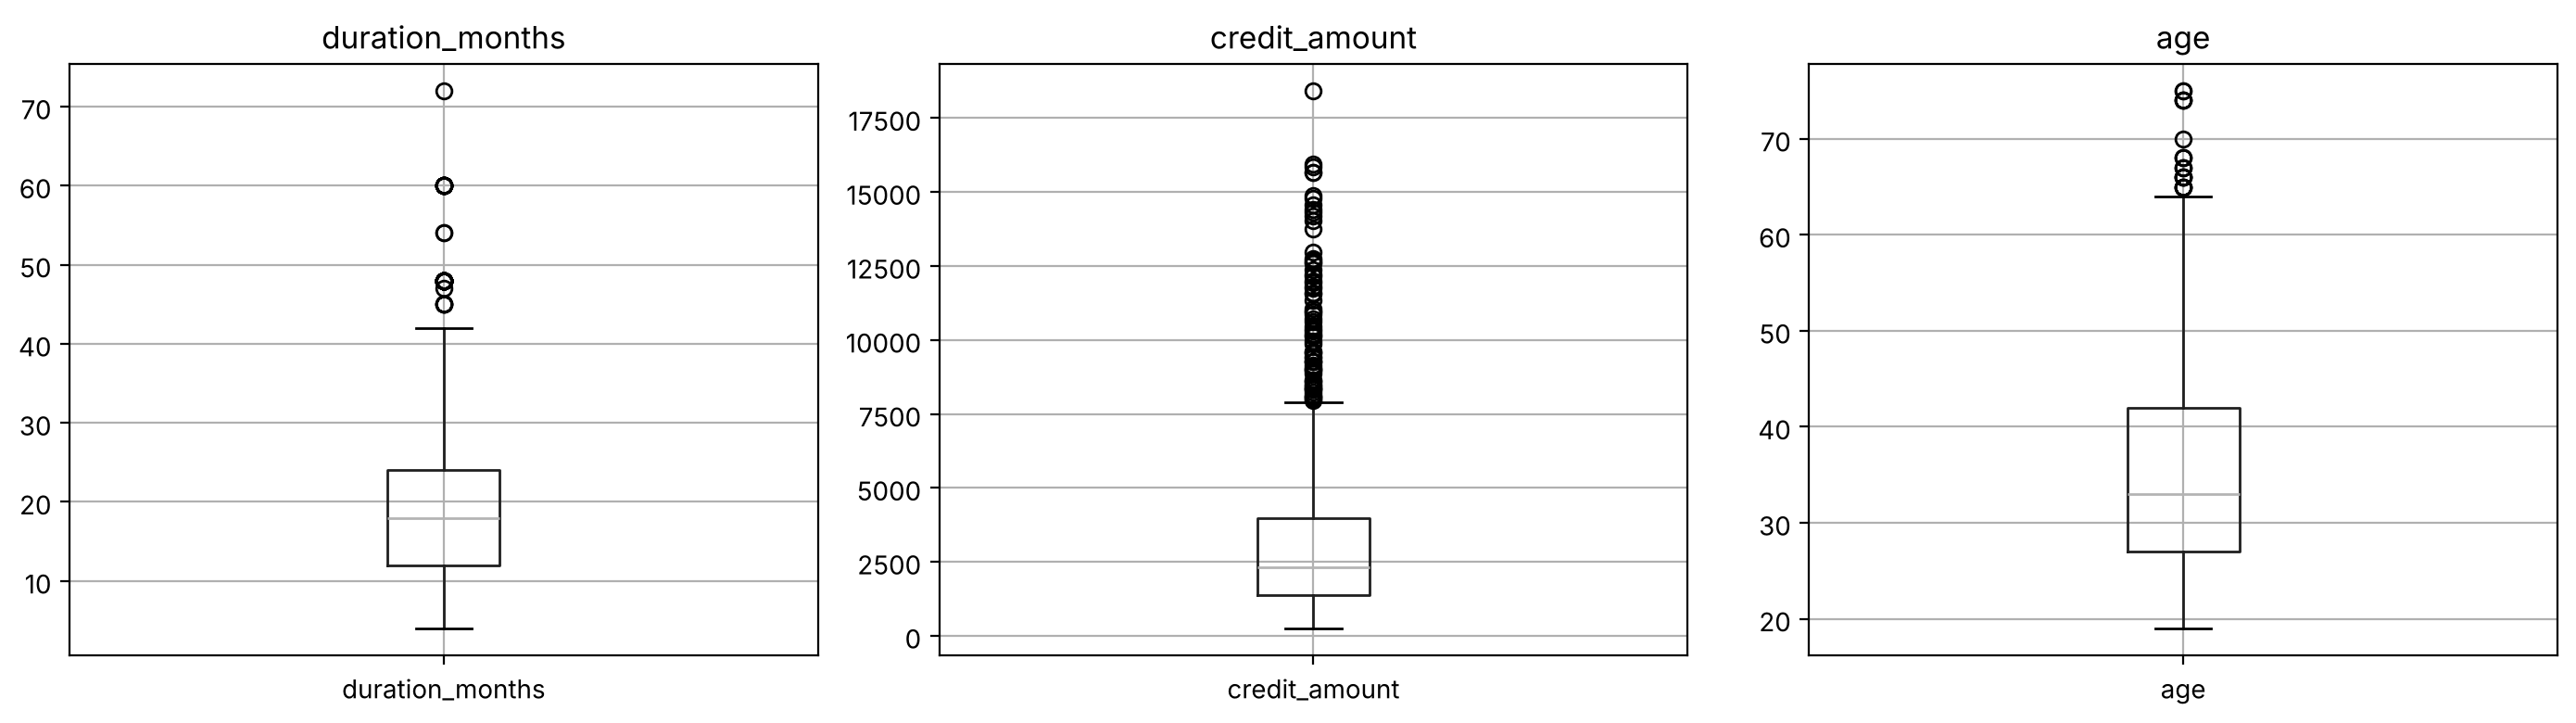

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["duration_months", "credit_amount", "age"]):
    X.boxplot(column=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("figures/outliers.png", dpi=150, bbox_inches="tight")
plt.show()

Long loans and large loans are outliers by the IQR rule, but they are real loans and they default at almost twice the normal rate. Removing them would throw away the riskiest applicants, so we keep them. Scaling handles the size difference. `num_dependents` only takes the values 1 and 2, so the IQR rule flags every 2 as an outlier. That is a reminder that the rule should not be applied blindly.

## 4. Explore the data

Missing values: 0
default
0    0.7
1    0.3
Name: proportion, dtype: float64


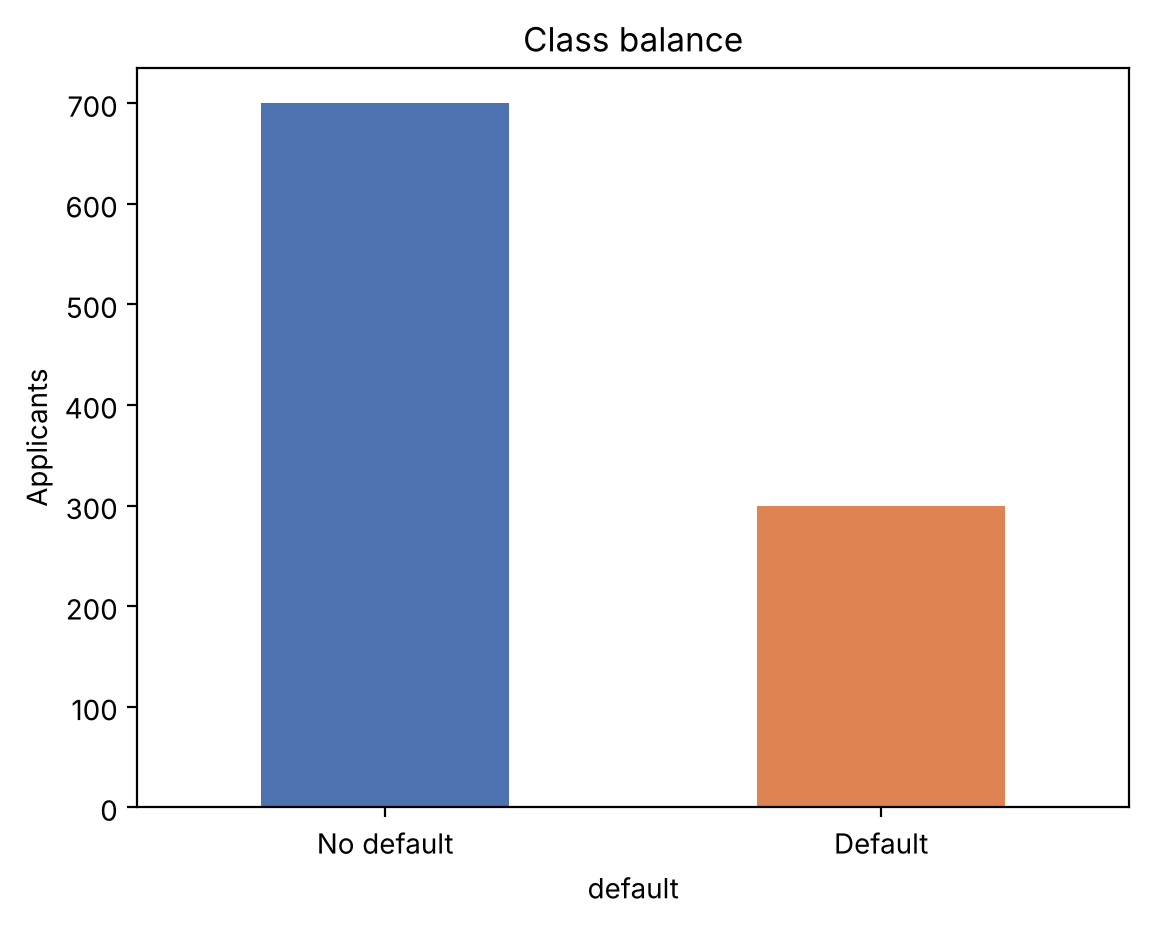

In [9]:
print("Missing values:", X.isnull().sum().sum())
print(y.value_counts(normalize=True))

y.map({0: "No default", 1: "Default"}).value_counts().plot(kind="bar", rot=0, color=["#4C72B0", "#DD8452"])
plt.title("Class balance")
plt.ylabel("Applicants")
plt.savefig("figures/class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

Only 30% of applicants default. A model that always says "no default" would already be 70% accurate, which is why accuracy alone is a bad score here.

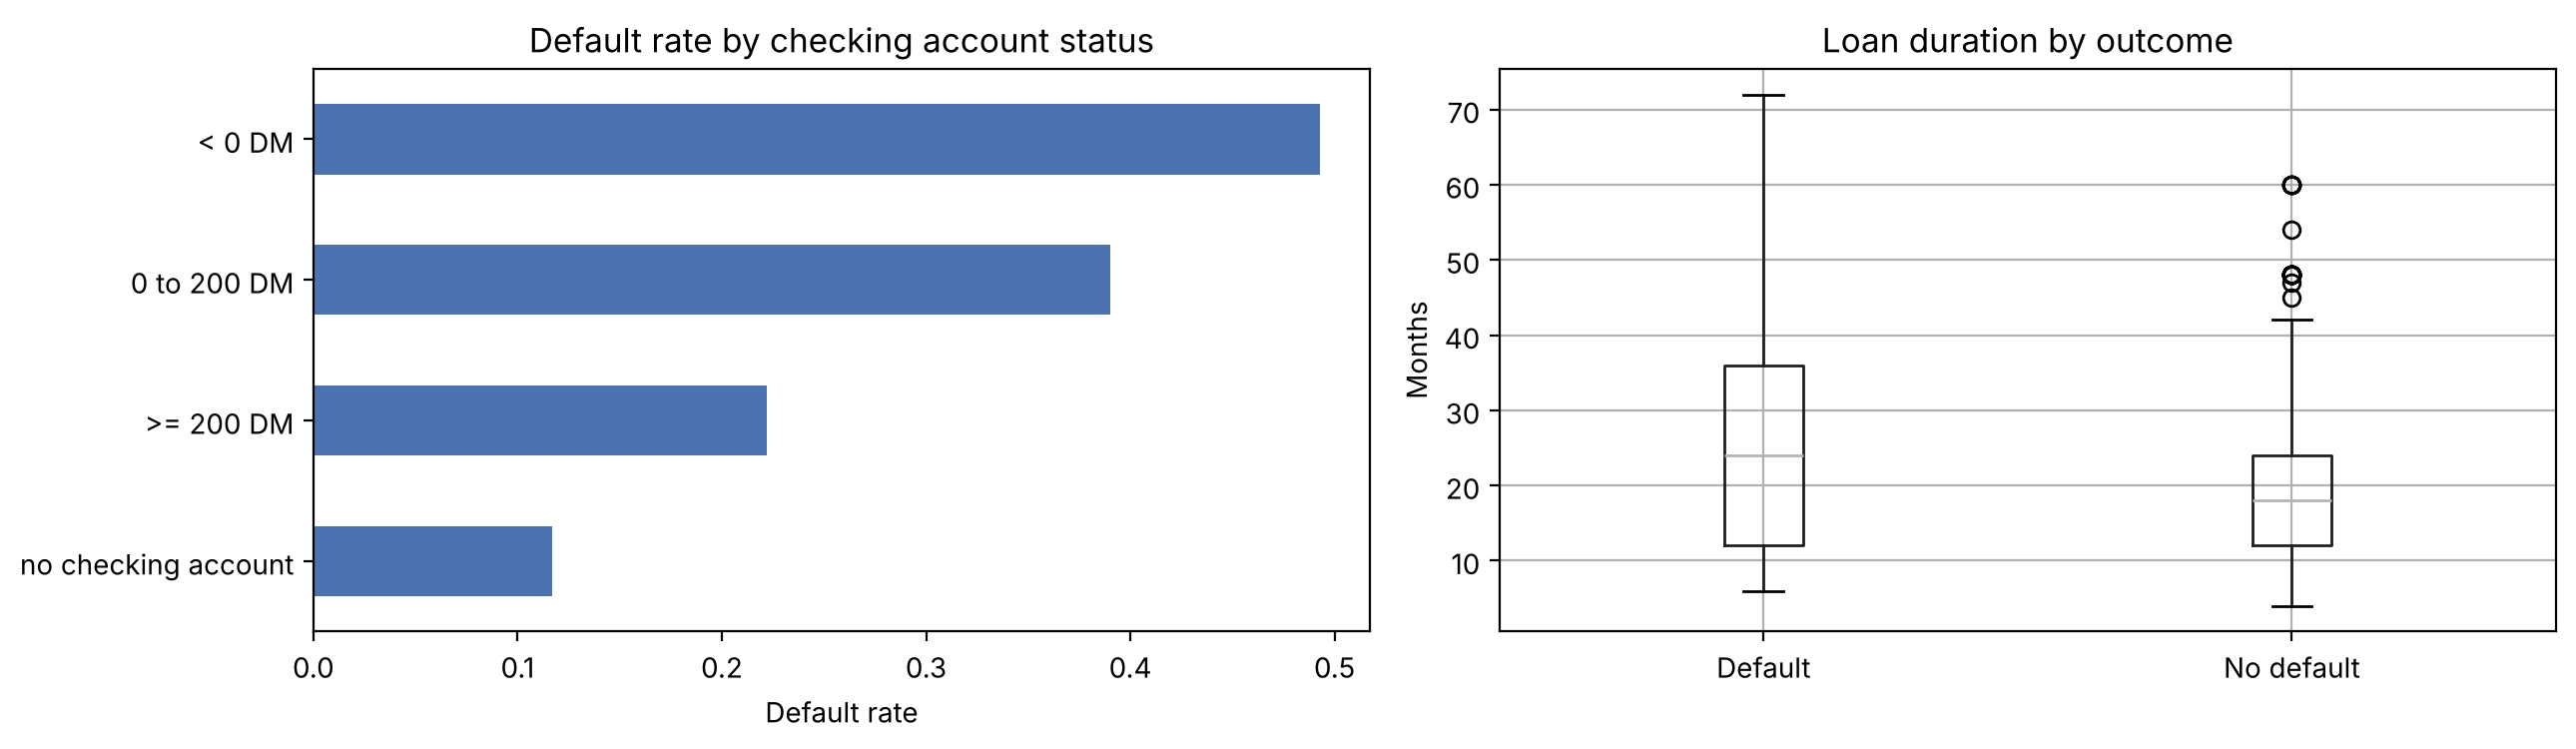

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

rate = y.groupby(X["status_checking"]).mean().sort_values()
rate.plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Default rate by checking account status")
axes[0].set_xlabel("Default rate")
axes[0].set_ylabel("")

X.assign(default=y.map({0: "No default", 1: "Default"})).boxplot(
    column="duration_months", by="default", ax=axes[1])
axes[1].set_title("Loan duration by outcome")
axes[1].set_xlabel("")
axes[1].set_ylabel("Months")
fig.suptitle("")

plt.tight_layout()
plt.savefig("figures/eda.png", dpi=150, bbox_inches="tight")
plt.show()

Applicants with a negative checking balance default far more often, and defaulters tend to take longer loans. So the features carry real signal.

## 5. Train/test split

`stratify=y` keeps the same 70/30 ratio in both sets.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (800, 20) Test: (200, 20)


## 6. Preprocessing, models and metrics

Numeric columns are scaled and categorical columns are one-hot encoded. We also add an imputer in front of each (median for numbers, most common value for categories). This data has no blanks, so it changes nothing here, but a new applicant with a missing field would still get a prediction. All of these steps sit inside a `Pipeline`, so they are fitted on the training data only and the test set never leaks into training.

For metrics, default is the positive class. Recall (also called sensitivity) is the share of real defaulters we catch. Specificity is the share of good applicants we correctly approve.

In [12]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

def make_prep():
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

def make_models(class_weight=None):
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight=class_weight),
        "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight=class_weight, random_state=42),
        "Random Forest": RandomForestClassifier(class_weight=class_weight, random_state=42),
    }
    return {name: Pipeline([("prep", make_prep()), ("clf", clf)]) for name, clf in models.items()}

def train(class_weight=None):
    return {name: pipe.fit(X_train, y_train) for name, pipe in make_models(class_weight).items()}

def metrics(models):
    rows = {}
    for name, m in models.items():
        pred = m.predict(X_test)
        rows[name] = {"Accuracy": accuracy_score(y_test, pred),
                      "Precision": precision_score(y_test, pred),
                      "Recall": recall_score(y_test, pred),
                      "Specificity": recall_score(y_test, pred, pos_label=0),
                      "F1": f1_score(y_test, pred)}
    return pd.DataFrame(rows).T.round(3)

def plot_confusion(models, path):
    fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), squeeze=False)
    for ax, (name, m) in zip(axes[0], models.items()):
        cm = confusion_matrix(y_test, m.predict(X_test))
        ConfusionMatrixDisplay(cm, display_labels=["No default", "Default"]).plot(ax=ax, colorbar=False)
        ax.set_title(name)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

## 7. Baseline models

In [13]:
baseline = train()
base_table = metrics(baseline)
base_table

,Accuracy,Precision,Recall,Specificity,F1
Logistic Regression,0.780,0.667,0.533,0.886,0.593
Decision Tree,0.645,0.420,0.483,0.714,0.450
Random Forest,0.780,0.735,0.417,0.936,0.532


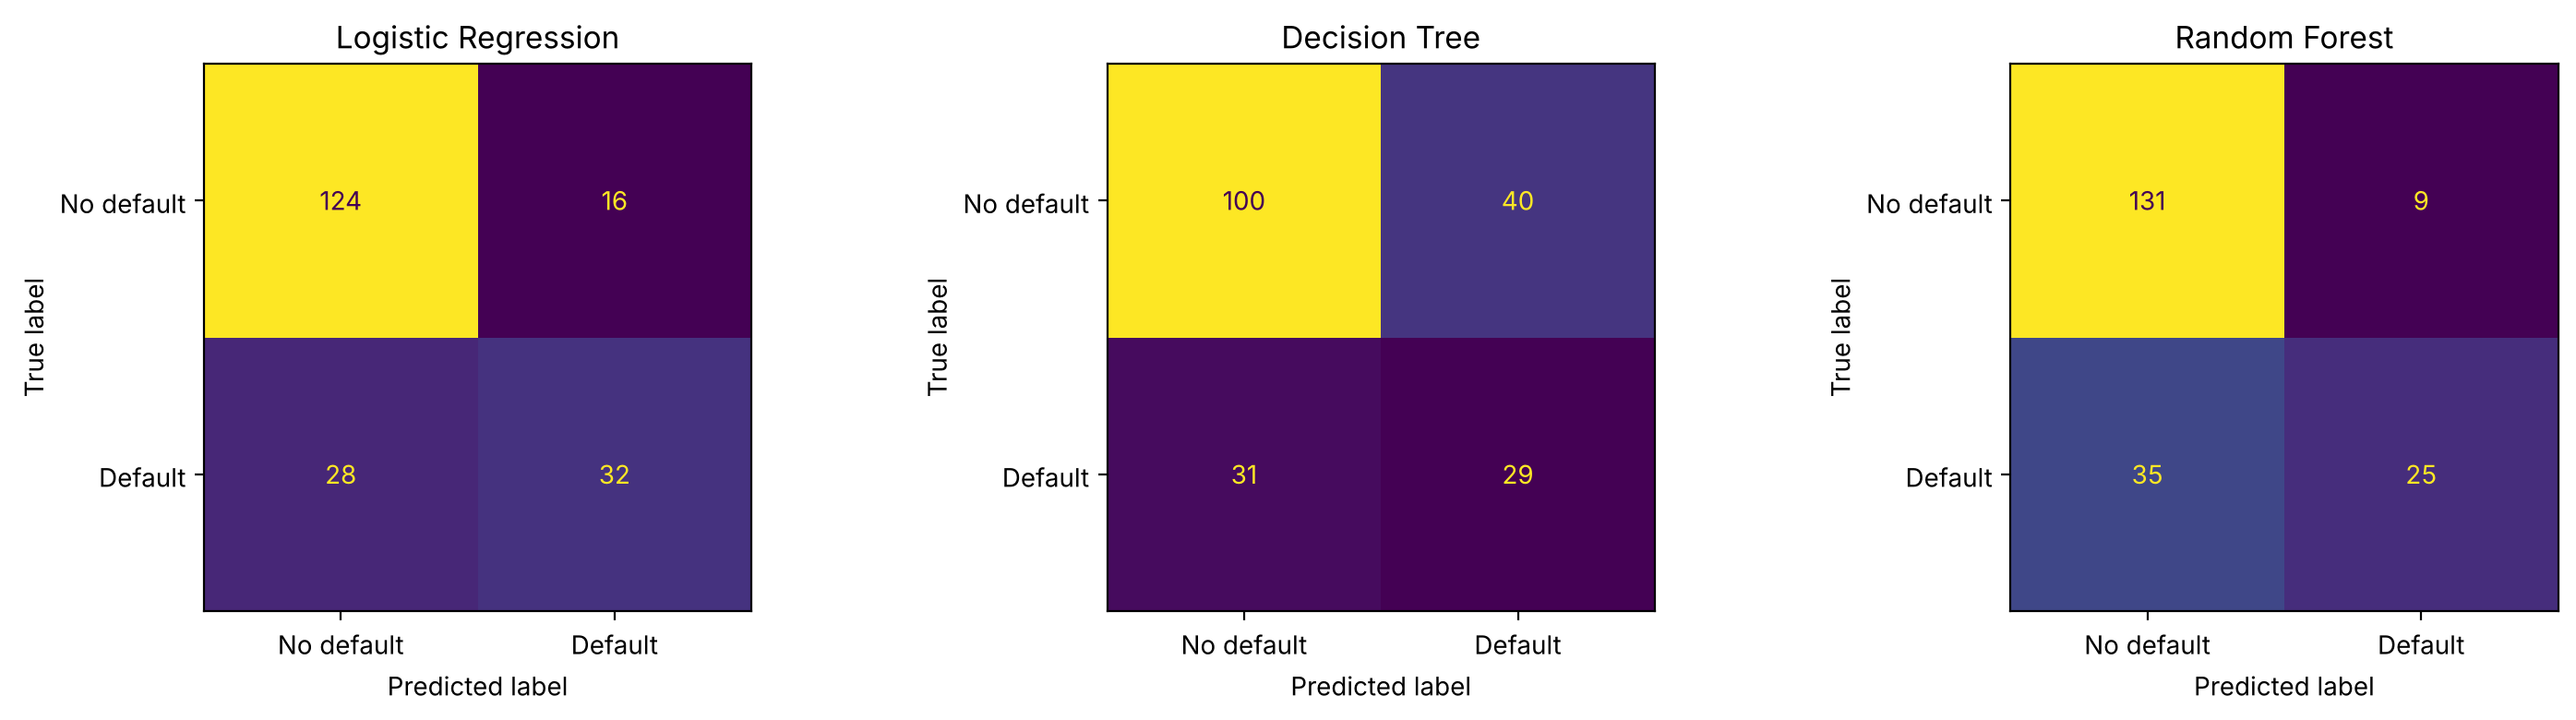

In [14]:
plot_confusion(baseline, "figures/cm_baseline.png")

The bottom-left cell of each matrix is the number of defaulters the model missed (false negatives). Logistic Regression has the best baseline recall at about 0.53, so it still lets almost half of the defaulters through.

## 8. Fixing the class imbalance

With `class_weight="balanced"` each class gets a weight inversely proportional to how often it appears, so a mistake on a defaulter costs about 2.3 times more than a mistake on a good applicant during training.

In [15]:
balanced = train(class_weight="balanced")
bal_table = metrics(balanced)
bal_table

,Accuracy,Precision,Recall,Specificity,F1
Logistic Regression,0.75,0.558,0.800,0.729,0.658
Decision Tree,0.57,0.377,0.667,0.529,0.482
Random Forest,0.77,0.617,0.617,0.836,0.617


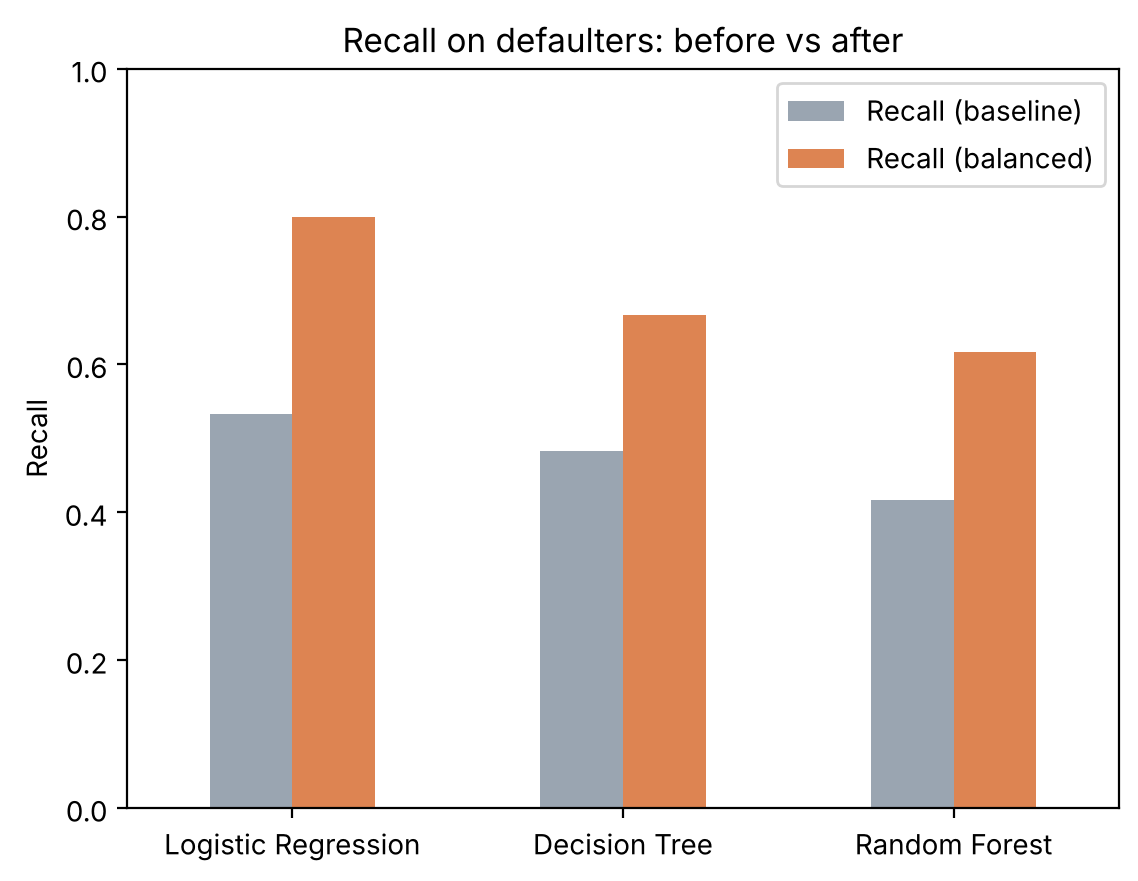

,Recall (baseline),Recall (balanced)
Logistic Regression,0.533,0.800
Decision Tree,0.483,0.667
Random Forest,0.417,0.617


In [16]:
compare = pd.DataFrame({"Recall (baseline)": base_table["Recall"],
                        "Recall (balanced)": bal_table["Recall"]})
compare.plot(kind="bar", rot=0, color=["#9AA5B1", "#DD8452"])
plt.title("Recall on defaulters: before vs after")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.savefig("figures/recall_compare.png", dpi=150, bbox_inches="tight")
plt.show()
compare

Recall goes up for all three models. Logistic Regression goes from 0.53 to 0.80 and keeps the best F1. The price is specificity and precision: the model now rejects more good applicants (specificity drops from 0.89 to 0.73), which is the trade we want in lending. The Decision Tree gains recall but loses a lot of accuracy, so it ends up the weakest model.

## 9. Is this just a lucky split?

One 80/20 split is only 60 defaulters in the test set. We repeat the balanced training with 5-fold stratified cross-validation on all 1000 rows to check that the numbers hold.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "specificity": make_scorer(recall_score, pos_label=0), "f1": "f1"}
rows = {}
for name, pipe in make_models("balanced").items():
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    rows[name] = {m: f"{scores['test_' + m].mean():.3f} ± {scores['test_' + m].std():.3f}"
                  for m in scoring}
cv_table = pd.DataFrame(rows).T
cv_table

,accuracy,precision,recall,specificity,f1
Logistic Regression,0.719 ± 0.027,0.524 ± 0.034,0.720 ± 0.041,0.719 ± 0.029,0.606 ± 0.034
Decision Tree,0.636 ± 0.037,0.435 ± 0.029,0.660 ± 0.077,0.626 ± 0.080,0.520 ± 0.021
Random Forest,0.735 ± 0.012,0.561 ± 0.022,0.547 ± 0.016,0.816 ± 0.018,0.553 ± 0.014


## 10. Final model

Balanced Logistic Regression has the highest recall and F1, and it is also the easiest to explain: every feature gets one weight, and a positive weight pushes the applicant towards default. In lending that matters, since a bank has to be able to say why an application was rejected.

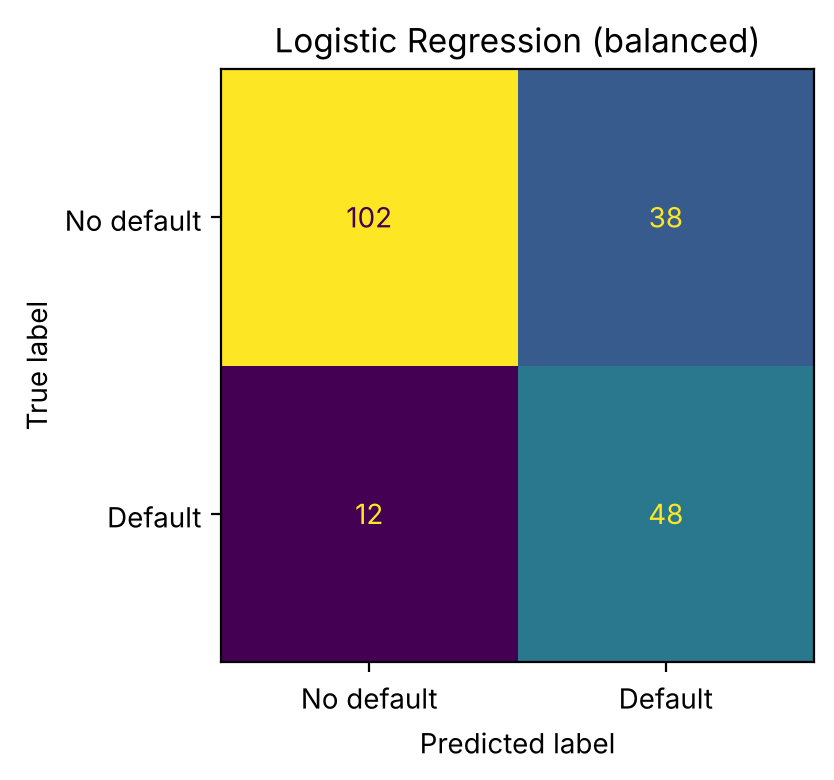

In [18]:
final = balanced["Logistic Regression"]
plot_confusion({"Logistic Regression (balanced)": final}, "figures/cm_final.png")

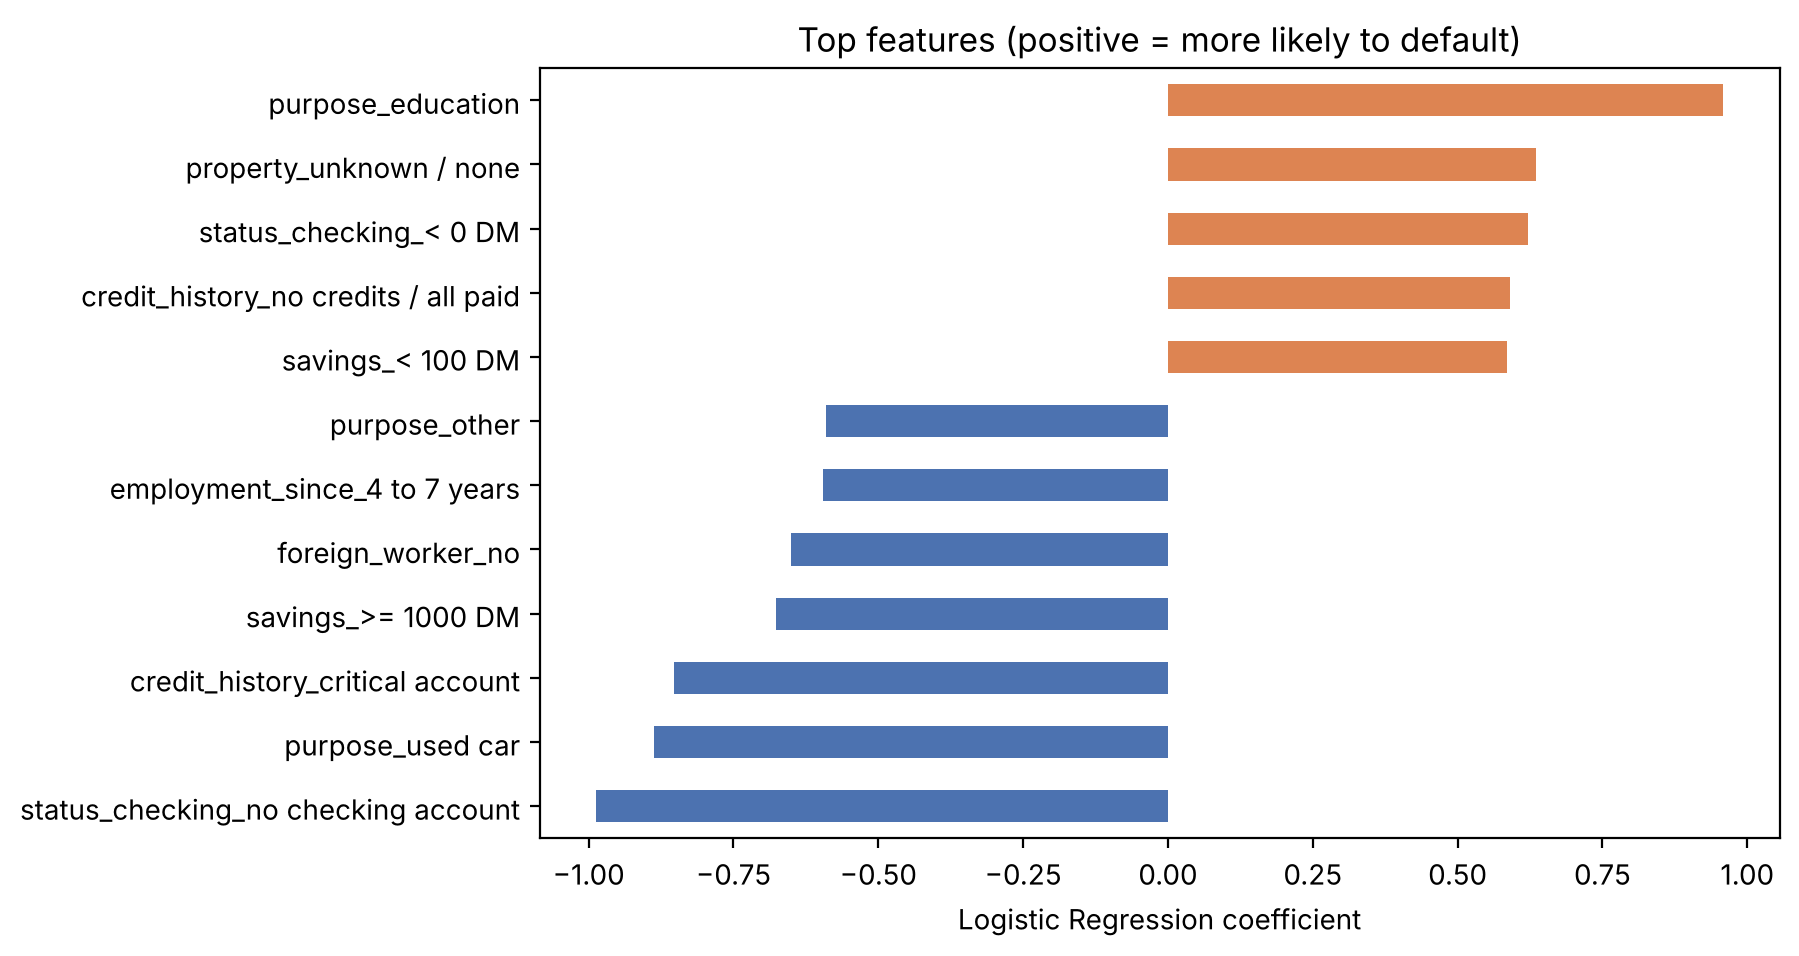

In [19]:
names = final.named_steps["prep"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
coef = pd.Series(final.named_steps["clf"].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:12]).sort_values()

top.plot(kind="barh", color=["#4C72B0" if v < 0 else "#DD8452" for v in top], figsize=(8, 5))
plt.title("Top features (positive = more likely to default)")
plt.xlabel("Logistic Regression coefficient")
plt.savefig("figures/top_features.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Predict a new applicant

We start from a typical applicant (median for numeric columns, most common value for categorical ones) and change a few fields to see how the final model scores them.

In [20]:
defaults = {c: (X_train[c].median() if c in num_cols else X_train[c].mode()[0]) for c in X.columns}

In [21]:
applicant = pd.DataFrame([defaults])[X.columns]
applicant["credit_amount"] = 9000
applicant["duration_months"] = 36
applicant["status_checking"] = "< 0 DM"

for name, m in balanced.items():
    p = m.predict_proba(applicant)[0, 1]
    print(f"{name}: {p:.0%} default risk -> {'DEFAULT' if p >= 0.5 else 'OK'}")

Logistic Regression: 81% default risk -> DEFAULT
Decision Tree: 83% default risk -> DEFAULT
Random Forest: 82% default risk -> DEFAULT


## Summary

1. The data has no blank cells or duplicates. Hidden missing values ("unknown" savings or property) and outliers (long, large loans) were kept on purpose, because both carry default signal.
2. Accuracy misleads because 70% of applicants don't default, so recall on defaulters is the metric that matters.
3. `class_weight="balanced"` makes a missed defaulter cost more during training. Recall (sensitivity) for Logistic Regression rises from 0.53 to 0.80 while specificity falls from 0.89 to 0.73, and cross-validation shows this is not a lucky split.
4. Random Forest gains less from class weights. Its trees grow until each leaf is almost pure, so the weights change its decisions less than they change a linear model.
5. Scaling and encoding live inside the `Pipeline`, so they only ever see training data.
6. The final model is balanced Logistic Regression: best recall, best F1, and easy to explain.